# H&M 고객 구매 패턴과 RFM 세분화

[H&M Kaggle 대회 데이터](https://www.kaggle.com/competitions/h-and-m-personalized-fashion-recommendations/data)로 구매 패턴을 분석한다. 시드 42로 고객 최대 10,000명을 추출하고, 거래 CSV를 나누어 읽으면서 선정 고객의 전체 기간 거래를 보존한다. 표본 내 구매 활동이 확인된 고객만 분석에 포함된다.

In [1]:
import sys
from pathlib import Path

from IPython.display import Markdown, display

root = Path.cwd()
if not (root / "src" / "pipeline.py").is_file():
    root = root.parent
sys.path.insert(0, str(root))

from src.pipeline import DataAnalyzer

analyzer = DataAnalyzer(root / "data" / "raw")
purchases = analyzer.load_data()
assert purchases.shape[0] >= 1000 and purchases.shape[1] >= 8
assert purchases["t_dat"].dtype.kind == "M"
assert purchases["sales_channel_id"].dtype.name == "category"
assert purchases["price"].dtype.kind in "fiu"
display(purchases.drop(columns=["customer_id", "article_id", "prod_name"]).head())
purchases.info()
display(purchases.describe())
display(purchases.isna().sum().to_frame("Missing"))

transaction_count, column_count = purchases.shape
buyer_count = purchases["customer_id"].nunique()
display(Markdown(
    f"구매 고객 **{buyer_count:,}명**의 거래 **{transaction_count:,}행**, **{column_count}개 컬럼**을 확보했다. "
    f"고객당 평균 {transaction_count / buyer_count:.1f}행이므로 고객 수와 상품 구매 기록 수를 구분한다."
))

<class 'pandas.DataFrame'>
RangeIndex: 226767 entries, 0 to 226766
Data columns (total 13 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   t_dat                   226767 non-null  datetime64[us]
 1   customer_id             226767 non-null  string        
 2   article_id              226767 non-null  string        
 3   price                   226767 non-null  float64       
 4   sales_channel_id        226767 non-null  category      
 5   club_member_status      226307 non-null  category      
 6   fashion_news_frequency  225750 non-null  category      
 7   age                     225883 non-null  float64       
 8   prod_name               226767 non-null  string        
 9   product_type_name       226767 non-null  category      
 10  product_group_name      226767 non-null  category      
 11  colour_group_name       226767 non-null  category      
 12  index_group_name        226767 non-null  

,t_dat,price,age
count,226767,226767.000000,225883.000000
mean,2019-09-15 05:34:44.827157,0.027572,35.739715
min,2018-09-20 00:00:00,0.000390,16.000000
25%,2019-03-28 00:00:00,0.015237,25.000000
50%,2019-08-23 00:00:00,0.025407,31.000000
75%,2020-03-27 00:00:00,0.033881,47.000000
max,2020-09-22 00:00:00,0.493220,92.000000
std,NaN,0.018745,12.908585


,Missing
t_dat,0
customer_id,0
article_id,0
price,0
sales_channel_id,0
club_member_status,460
fashion_news_frequency,1017
age,884
prod_name,0
product_type_name,0


구매 고객 **9,925명**의 거래 **226,767행**, **13개 컬럼**을 확보했다. 고객당 평균 22.8행이므로 고객 수와 상품 구매 기록 수를 구분한다.

## 결측치와 상품 피처

고객의 나이는 거래 횟수에 따라 가중되지 않도록 고객당 한 행으로 계산한다. 멤버십 상태별 중앙값으로 대치하고, 그룹에 관측값이 없으면 전체 고객 중앙값을 사용한다. 원본 나이는 대치 여부를 확인할 수 있도록 보존한다.

상품명에서 글자 수와 단어 수를 구한다. 표본 거래에 등장하는 상품 중 로컬에서 이미지를 찾을 수 있는 상품을 시드 42로 최대 500개 선택한다. 각 이미지의 가로·세로 전체에서 32개 픽셀 위치를 균등하게 골라 RGB 배열을 만들고, 0~1로 정규화하여 평균과 모집단 표준편차를 계산한다. 회색조는 같은 값을 RGB 세 채널에 사용한다. 추출하지 않은 이미지 피처는 결측으로 유지한다.

In [2]:
customers = purchases.drop_duplicates("customer_id").copy()
customers["age_filled"] = analyzer.handle_missing_values(
    customers, "age", "club_member_status"
)
display(customers[["age", "age_filled"]].isna().agg(["sum", "mean"]).T)
display(customers.groupby("club_member_status", observed=True, dropna=False)["age"].agg(
    customers="size", observed_ages="count", median="median"
))

purchases["age_filled"] = purchases["customer_id"].map(
    customers.set_index("customer_id")["age_filled"]
)
purchases = analyzer.add_text_features(purchases)
purchases = analyzer.add_image_features(purchases)
display(purchases[["product_name_length", "product_name_word_count", "image_mean", "image_std"]].describe())

before = customers["age"].isna()
after = customers["age_filled"].isna()
image_products = purchases.loc[purchases["image_mean"].notna(), "article_id"].nunique()
display(Markdown(
    f"나이 결측은 고객 {before.sum():,}명({before.mean():.1%})에서 "
    f"{after.sum():,}명({after.mean():.1%})으로 바뀌었다. 대치한 나이가 포함되므로 "
    f"나이와 가격의 관계는 실제 나이가 확인된 고객만으로도 비교할 필요가 있다. "
    f"이미지 피처는 **{image_products:,}개 상품**에서 얻었다. 이미지 관련 통계의 범위는 이 상품들로 제한된다."
))

,sum,mean
age,105.0,0.010579
age_filled,0.0,0.000000


,customers,observed_ages,median
club_member_status,,,
ACTIVE,9214,9173,31.0
LEFT CLUB,3,3,24.0
PRE-CREATE,671,617,41.0
NaN,37,27,36.0


Matplotlib is building the font cache; this may take a moment.


,product_name_length,product_name_word_count,image_mean,image_std
count,226767.0,226767.000000,2407.000000,2407.000000
mean,15.347537,2.728188,0.758532,0.235335
std,6.251137,1.128791,0.105837,0.114119
min,1.0,1.000000,0.167532,0.013123
25%,11.0,2.000000,0.686940,0.135789
50%,15.0,3.000000,0.769752,0.257825
75%,20.0,3.000000,0.848236,0.332630
max,30.0,8.000000,0.984466,0.443365


나이 결측은 고객 105명(1.1%)에서 0명(0.0%)으로 바뀌었다. 대치한 나이가 포함되므로 나이와 가격의 관계는 실제 나이가 확인된 고객만으로도 비교할 필요가 있다. 이미지 피처는 **500개 상품**에서 얻었다. 이미지 관련 통계의 범위는 이 상품들로 제한된다.

## IQR 가격 이상치

원본 거래 가격에서 Q1과 Q3를 계산하고, IQR의 1.5배를 기준으로 탐지한다. 시각 비교용 가격만 상한과 하한으로 제한한다. 고가 구매가 실제일 수 있으므로 RFM과 월별 금액 합계는 원본 가격을 사용한다.

In [3]:
q1, q3, lower, upper, price_outliers = analyzer.detect_outliers(purchases, "price")
purchases["price_clipped"] = purchases["price"].clip(lower, upper)
display({
    "Q1": q1, "Q3": q3, "IQR": q3 - q1, "Lower": lower, "Upper": upper,
    "Outliers": int(price_outliers.sum()), "Outlier share": price_outliers.mean(),
})

{'Q1': 0.0152372881355932,
 'Q3': 0.0338813559322033,
 'IQR': 0.018644067796610105,
 'Lower': -0.012728813559321957,
 'Upper': 0.06184745762711846,
 'Outliers': 10095,
 'Outlier share': np.float64(0.04451705936048896)}

## 구매 패턴과 변수 간 관계

가격은 데이터셋에서 제공하는 척도로 표시한다. 거래 행은 개별 상품 구매 기록이다. 상관계수는 각 변수 쌍의 관측값을 이용한 Pearson 계수이며, 동일 고객과 상품의 반복 거래가 포함된다.

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["price", "age_filled", "product_name_length", "image_mean", "image_std"]
summary, correlations = analyzer.summarize(purchases, columns)
display(summary)
display(correlations["price"].drop("price").to_frame("Pearson r"))

,count,mean,std,min,25%,50%,75%,max
price,226767.0,0.027572,0.018745,0.00039,0.015237,0.025407,0.033881,0.49322
age_filled,226767.0,35.735548,12.886834,16.0,25.0,31.0,47.0,92.0
product_name_length,226767.0,15.347537,6.251137,1.0,11.0,15.0,20.0,30.0
image_mean,2407.0,0.758532,0.105837,0.167532,0.68694,0.769752,0.848236,0.984466
image_std,2407.0,0.235335,0.114119,0.013123,0.135789,0.257825,0.33263,0.443365


,Pearson r
age_filled,0.042114
product_name_length,-0.014828
image_mean,-0.177009
image_std,0.129627


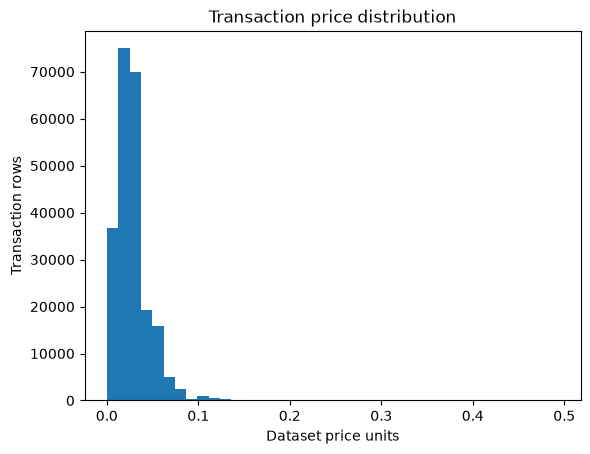

거래 가격 평균은 **0.0276**, 중앙값은 **0.0254**다. 평균과 중앙값을 함께 보면 대표 가격대를 판단할 때 극단 가격의 영향을 구분할 수 있다.

In [5]:
fig, ax = plt.subplots()
ax.hist(purchases["price"], bins=40)
ax.set(title="Transaction price distribution", xlabel="Dataset price units", ylabel="Transaction rows")
plt.show()

average = summary.loc["price", "mean"]
median = summary.loc["price", "50%"]
display(Markdown(
    f"거래 가격 평균은 **{average:.4f}**, 중앙값은 **{median:.4f}**다. "
    f"평균과 중앙값을 함께 보면 대표 가격대를 판단할 때 극단 가격의 영향을 구분할 수 있다."
))

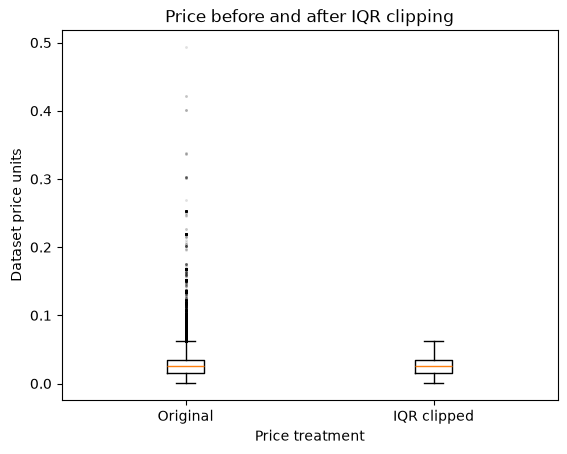

IQR 범위 밖 거래는 **10,095행(4.5%)**이다. 제한 전후 최대값은 0.4932 → 0.0618다. 가격 분포 비교에는 제한값을 쓰고, 고가 구매의 기여도는 원본 가격을 합산하여 평가한다.

In [6]:
fig, ax = plt.subplots()
ax.boxplot([purchases["price"], purchases["price_clipped"]], flierprops={"markersize": 1, "alpha": 0.12})
ax.set_xticks([1, 2], ["Original", "IQR clipped"])
ax.set(title="Price before and after IQR clipping", xlabel="Price treatment", ylabel="Dataset price units")
plt.show()

display(Markdown(
    f"IQR 범위 밖 거래는 **{price_outliers.sum():,}행({price_outliers.mean():.1%})**이다. "
    f"제한 전후 최대값은 {purchases['price'].max():.4f} → {purchases['price_clipped'].max():.4f}다. "
    "가격 분포 비교에는 제한값을 쓰고, 고가 구매의 기여도는 원본 가격을 합산하여 평가한다."
))

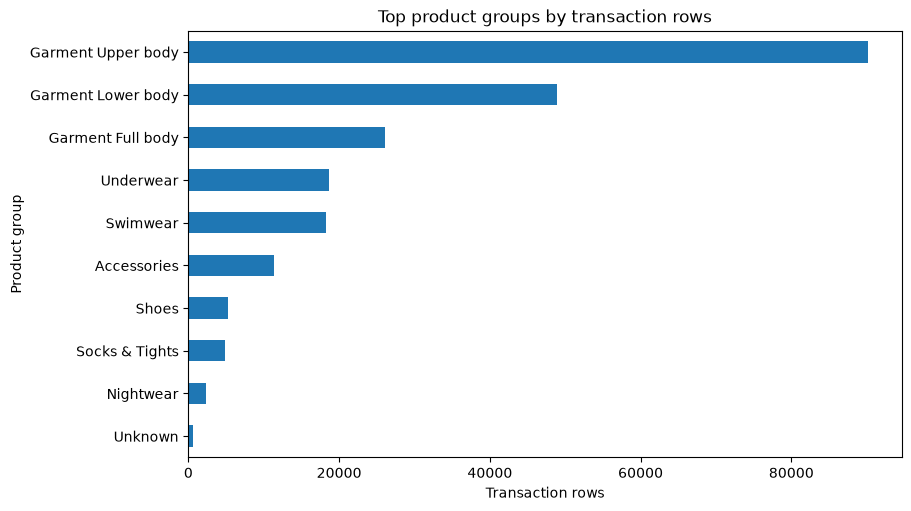

가장 자주 거래된 상품군은 **Garment Upper body**로 거래 90,130행을 차지했다. 이 상품군은 재고와 구색을 먼저 점검할 후보이며, 실제 재고 결정에는 반품과 품절 정보도 필요하다.

In [7]:
top_groups = purchases["product_group_name"].value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
top_groups.sort_values().plot.barh(ax=ax)
ax.set(title="Top product groups by transaction rows", xlabel="Transaction rows", ylabel="Product group")
plt.show()

display(Markdown(
    f"가장 자주 거래된 상품군은 **{top_groups.index[0]}**로 거래 {top_groups.iloc[0]:,}행을 차지했다. "
    "이 상품군은 재고와 구색을 먼저 점검할 후보이며, 실제 재고 결정에는 반품과 품절 정보도 필요하다."
))

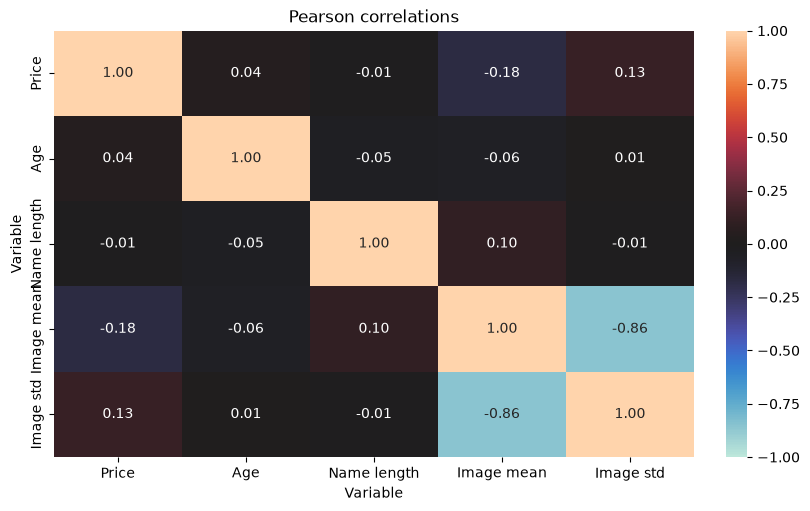

가격과 상품명 길이의 상관은 **-0.015**, 가격과 이미지 평균의 상관은 **-0.177**이다. 이름이나 이미지 활용 전략을 검토할 때 상품군과 가격대가 비슷한 상품끼리 비교해도 같은 관계가 유지되는지 확인해야 한다.

In [8]:
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
chart_labels = ["Price", "Age", "Name length", "Image mean", "Image std"]
sns.heatmap(correlations, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            xticklabels=chart_labels, yticklabels=chart_labels, ax=ax)
ax.set(title="Pearson correlations", xlabel="Variable", ylabel="Variable")
plt.show()

name_price_r = correlations.loc["product_name_length", "price"]
image_price_r = correlations.loc["image_mean", "price"]
display(Markdown(
    f"가격과 상품명 길이의 상관은 **{name_price_r:.3f}**, 가격과 이미지 평균의 상관은 "
    f"**{image_price_r:.3f}**이다. 이름이나 이미지 활용 전략을 검토할 때 "
    "상품군과 가격대가 비슷한 상품끼리 비교해도 같은 관계가 유지되는지 확인해야 한다."
))

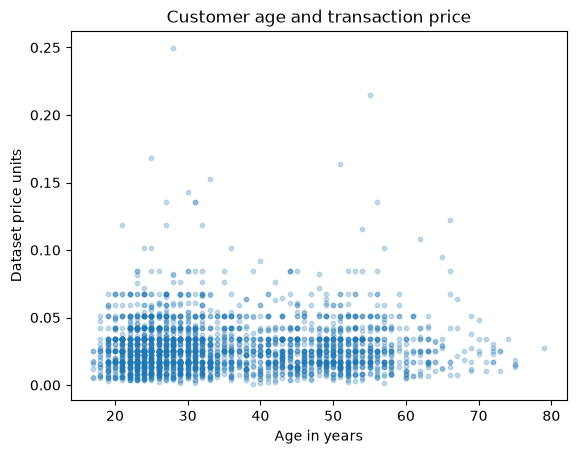

산점도에는 시드 42로 추출한 **3,000행**을 표시했다. 전체 표본의 나이와 가격 상관은 **0.042**이다. 나이 기반 캠페인에 적용하기 전에 고객 단위로 집계하고 실제 나이가 관측된 고객에서도 관계를 확인해야 한다.

In [9]:
points = purchases.sample(n=min(3000, len(purchases)), random_state=42)
fig, ax = plt.subplots()
ax.scatter(points["age_filled"], points["price"], alpha=0.25, s=10)
ax.set(title="Customer age and transaction price", xlabel="Age in years", ylabel="Dataset price units")
plt.show()

age_price_r = correlations.loc["age_filled", "price"]
display(Markdown(
    f"산점도에는 시드 42로 추출한 **{len(points):,}행**을 표시했다. "
    f"전체 표본의 나이와 가격 상관은 **{age_price_r:.3f}**이다. "
    "나이 기반 캠페인에 적용하기 전에 고객 단위로 집계하고 실제 나이가 관측된 고객에서도 관계를 확인해야 한다."
))

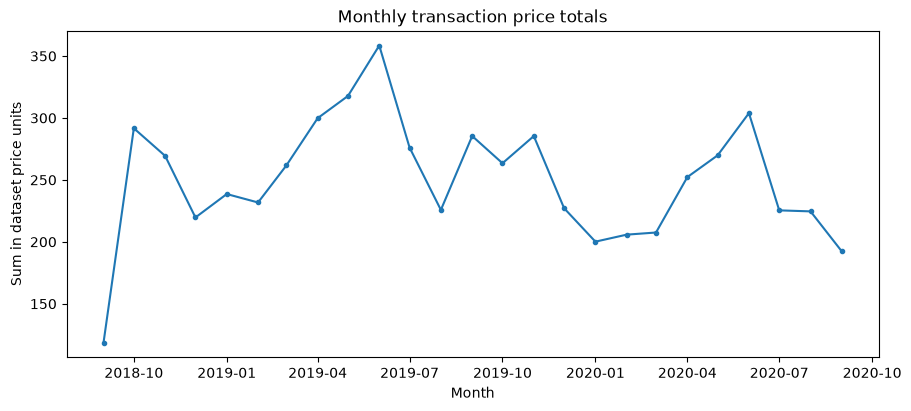

월별 거래 가격 합계가 가장 큰 달은 **2019-06**이고 합계는 **358.49**다. 이 달의 집중이 반복되는지 확인한 뒤 프로모션 시기 선정에 활용할 수 있다. 관측 기간 양끝의 불완전한 달은 월간 비교 시 주의한다.

In [10]:
monthly = purchases.groupby(purchases["t_dat"].dt.to_period("M"))["price"].sum()
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
ax.plot(monthly.index.to_timestamp(), monthly.values, marker=".")
ax.set(title="Monthly transaction price totals", xlabel="Month", ylabel="Sum in dataset price units")
plt.show()

display(Markdown(
    f"월별 거래 가격 합계가 가장 큰 달은 **{monthly.idxmax()}**이고 합계는 "
    f"**{monthly.max():,.2f}**다. 이 달의 집중이 반복되는지 확인한 뒤 프로모션 시기 선정에 활용할 수 있다. "
    "관측 기간 양끝의 불완전한 달은 월간 비교 시 주의한다."
))

## RFM 고객 세분화

기준일은 표본의 마지막 거래일이다. Recency는 기준일에서 마지막 구매일까지의 일수, Frequency는 서로 다른 구매일 수, Monetary는 원본 거래 가격의 합이다. 주문 ID가 없어 구매일 수는 구매 활동 빈도의 대리 지표로 사용한다.

각 지표를 백분위 순위로 변환하고 25% 간격으로 1~4점을 부여한다. 동률에는 평균 순위를 적용하고 Recency는 일수가 짧을수록 높은 점수를 부여한다. 분류는 위에서 아래 순서로 처음 충족한 규칙을 적용한다.

| 세그먼트 | 분류 기준 |
|---|---|
| VIP | R·F·M 모두 3점 이상이고 구매일이 2일 이상 |
| Loyal | R·F 3점 이상이고 구매일이 2일 이상인 나머지 고객 |
| New | R 3점 이상이며 기준일 직전 30일 이내에 관측된 구매일이 하루인 고객 |
| Churned | R 2점 이하인 장기 미구매 또는 이탈 위험 고객 |
| Active | 나머지 고객 |

New는 데이터 관측 기간 안의 분류다. Churned는 표본 내 상대적인 구매 공백을 기준으로 하며 실제 이탈 여부는 확인할 수 없다.

Reference date 2020-09-22


,customers,mean_recency,mean_frequency,mean_monetary,total_monetary,customer_share,monetary_share
segment,,,,,,,
Churned,4960,413.738,2.692,0.266,1320.392,50.0%,21.1%
VIP,3336,49.521,14.678,1.408,4696.195,33.6%,75.1%
Active,1010,81.924,1.487,0.140,141.762,10.2%,2.3%
Loyal,453,62.978,3.989,0.170,77.130,4.6%,1.2%
New,166,13.627,1.000,0.102,16.922,1.7%,0.3%


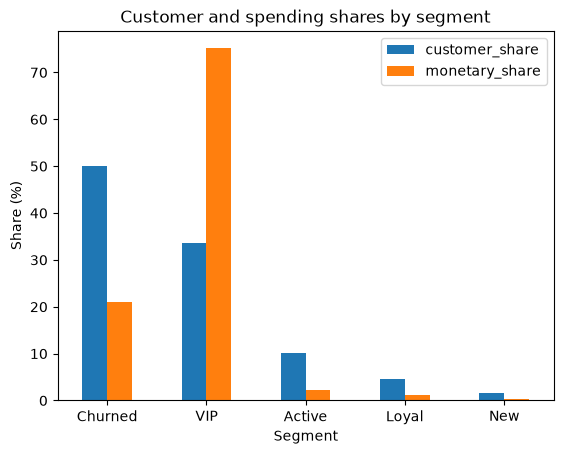

가장 큰 그룹은 **Churned**로 고객 4,960명(50.0%)과 구매금액 21.1%를 차지한다. 고객 비중과 금액 비중을 함께 비교하면 캠페인 도달 규모와 소비 기여도를 따로 판단할 수 있다.

In [11]:
import numpy as np

rfm = analyzer.calculate_rfm(purchases)
segments = analyzer.summarize_segments(rfm)
assert rfm.index.is_unique and rfm.index.size == purchases["customer_id"].nunique()
assert rfm["segment"].notna().all()
assert np.isclose(rfm["monetary"].sum(), purchases["price"].sum())
print("Reference date", rfm.attrs["reference_date"].date())
display(segments.style.format(precision=3, formatter={
    "customer_share": "{:.1%}", "monetary_share": "{:.1%}",
}))
fig, ax = plt.subplots()
segments[["customer_share", "monetary_share"]].mul(100).plot.bar(ax=ax, rot=0)
ax.set(title="Customer and spending shares by segment", xlabel="Segment", ylabel="Share (%)")
plt.show()

largest = segments.iloc[0]
display(Markdown(
    f"가장 큰 그룹은 **{segments.index[0]}**로 고객 {int(largest['customers']):,}명"
    f"({largest['customer_share']:.1%})과 구매금액 {largest['monetary_share']:.1%}를 차지한다. "
    "고객 비중과 금액 비중을 함께 비교하면 캠페인 도달 규모와 소비 기여도를 따로 판단할 수 있다."
))